# Live deep-learning demo: Nonspeech7k vocalisation recognition

Every number below is computed live from real audio and saved checkpoints; nothing is hard-coded.

* **CNN**: log-mel CNN trained from scratch (`train_cnn.py`).
* **AST, ordinary fine-tuning**: pretrained Audio Spectrogram Transformer (`MIT/ast-finetuned-audioset-10-10-0.4593`) with its last transformer block fine-tuned and a new 7-class head, cross-entropy only (`ast_finetune.py`).
* **AST, combined source-aware training**: same model and budget, trained with source-balanced sampling plus a cross-source supervised contrastive term (positives = same class, different recording source).

Test clips are drawn from the **source-disjoint test partition**: no recording they were cut from (and no duplicated copy of it) was seen in training or validation.

Scores shown are **raw softmax outputs, not calibrated probabilities**.

In [1]:
import os, sys, time
from pathlib import Path
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
REPO = Path.cwd().parent if Path.cwd().name == "professor_demo" else Path.cwd()
sys.path.insert(0, str(REPO))
# data and results live next to the repository; override with environment variables if moved
DATA = Path(os.environ.get("NS7K_DATA", REPO.parent / "data"))
RESULTS = Path(os.environ.get("NS7K_RESULTS", REPO.parent / "results" / "v3"))
from common import index_audio
from features import load_mono
from dl_data import CLASSES
print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available(), "| CPU threads:", torch.get_num_threads())
audio = index_audio(DATA / "audio")
splits = pd.read_csv(RESULTS / "dl" / "splits.csv")
print(len(audio), "audio files indexed;", len(splits), "clips in the split manifest")

torch 2.15.0+cpu | CUDA available: False | CPU threads: 4


7014 audio files indexed; 7014 clips in the split manifest


## 1. Pick a real test recording

In [2]:
test = splits[splits.source_disjoint == "test"]
rng = np.random.default_rng(int(os.environ.get("DEMO_SEED", 3)))
row = test.iloc[rng.integers(len(test))]
wave, sr = load_mono(audio[row.filename])
print(f"file {row.filename} | true class: {row.cls} | website: {row.source} | source group: {row.group}")
print(f"{len(wave)/sr:.2f} s at {sr} Hz")

file 405271-2_4_0.wav | true class: screaming | website: freesound | source group: fs:405271
4.00 s at 32000 Hz


## 2. Play it

In [3]:
from IPython.display import Audio, display
display(Audio(wave, rate=sr))

## 3. Waveform and log-mel spectrogram (the CNN's input)

C:\Users\ADMINI~1\AppData\Local\Temp\ns7kvenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


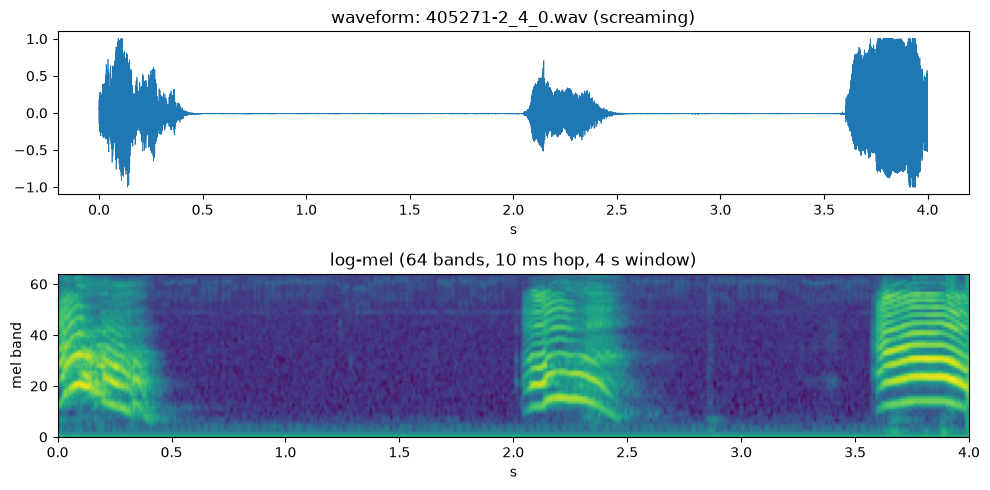

In [4]:
from inference import CNNClassifier, ASTClassifier
cnn_ck = RESULTS / "runs" / "cnn_source_disjoint_standard_s0" / "best.pt"
cnn = CNNClassifier(cnn_ck)
M = cnn.features(wave)
fig, ax = plt.subplots(2, 1, figsize=(10, 5))
ax[0].plot(np.arange(len(wave)) / sr, wave, lw=.5); ax[0].set(title=f"waveform: {row.filename} ({row.cls})", xlabel="s")
ax[1].imshow(M, origin="lower", aspect="auto", extent=[0, 4, 0, M.shape[0]]); ax[1].set(title="log-mel (64 bands, 10 ms hop, 4 s window)", xlabel="s", ylabel="mel band")
plt.tight_layout(); plt.show()

## 4. CNN inference

In [5]:
print(cnn.model)
print(f"trainable parameters: {cnn.n_params:,}; checkpoint epoch {cnn.info['epoch']} (selected on validation macro-F1)")
s_cnn, t_cnn = cnn.predict(wave)
print(f"CNN prediction: {CLASSES[s_cnn.argmax()]} (true: {row.cls}) | inference {1000*t_cnn:.1f} ms")
pd.Series(s_cnn, index=CLASSES).round(3).rename("raw softmax score").to_frame()

LogMelCNN(
  (features): Sequential(
    (0): ConvBlock(
      (net): Sequential(
        (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvBlock(
      (net): Sequential(
        (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (5): ReLU(inplace=True)
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
   

CNN prediction: crying (true: screaming) | inference 232.1 ms


,raw softmax score
breath,0.000
cough,0.004
crying,0.552
laugh,0.077
screaming,0.157
sneeze,0.195
yawn,0.015


## 5. Fine-tuned AST inference

C:\Users\ADMINI~1\AppData\Local\Temp\ns7kvenv\Lib\site-packages\transformers\audio_utils.py:860: UserWarning: At least one mel filter has all zero values. The value for `num_mel_filters` (128) may be set too high. Or, the value for `num_frequency_bins` (257) may be set too low.
  warnings.warn(


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   3%|▎         | 6/199 [00:00<00:03, 50.12it/s]

Loading weights:   6%|▌         | 12/199 [00:00<00:03, 48.35it/s]

Loading weights:   9%|▊         | 17/199 [00:00<00:03, 47.62it/s]

Loading weights:  11%|█         | 22/199 [00:00<00:03, 48.40it/s]

... (12 outputs left out)

Loading weights: 100%|██████████| 199/199 [00:01<00:00, 197.54it/s]


[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.layernorm.weight | UNEXPECTED |  | 
classifier.dense.weight     | UNEXPECTED |  | 
classifier.layernorm.bias   | UNEXPECTED |  | 
classifier.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


AST: 86,192,647 parameters; layers 0..10 frozen pretrained, layer 11..11 fine-tuned, new head
combined model: supcon weight 0.5 | sampler source


AST ordinary: screaming | AST combined: screaming | true: screaming | 6086 ms on CPU


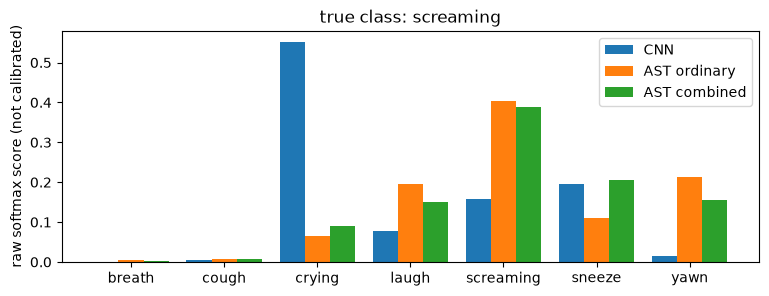

In [6]:
astc = ASTClassifier(RESULTS / "runs" / "ast_ft_source_disjoint_standard_s0" / "best.pt")    # ordinary
astm = ASTClassifier(RESULTS / "runs" / "ast_ftsc_source_disjoint_source_s0" / "best.pt")  # combined source-aware
print(f"AST: {astc.n_params:,} parameters; layers 0..{astc.k-1} frozen pretrained, layer {astc.k}..11 fine-tuned, new head")
print("combined model: supcon weight", astm.info["args"]["supcon"], "| sampler", astm.info["args"]["sampler"])
s_ast, t_ast = astc.predict(wave)
s_astm, t_astm = astm.predict(wave)
print(f"AST ordinary: {CLASSES[s_ast.argmax()]} | AST combined: {CLASSES[s_astm.argmax()]} | true: {row.cls} | {1000*t_ast:.0f} ms on CPU")
fig, ax = plt.subplots(figsize=(9, 3))
x = np.arange(len(CLASSES))
ax.bar(x - .27, s_cnn, .27, label="CNN"); ax.bar(x, s_ast, .27, label="AST ordinary"); ax.bar(x + .27, s_astm, .27, label="AST combined")
ax.set_xticks(x, CLASSES); ax.set_ylabel("raw softmax score (not calibrated)"); ax.set_title(f"true class: {row.cls}"); ax.legend(); plt.show()

## 6. Compare both models on several test recordings (one per class)

In [7]:
rows = []
for c in CLASSES:
    r = test[test.cls == c].sample(1, random_state=int(os.environ.get("DEMO_SEED", 3))).iloc[0]
    w, _ = load_mono(audio[r.filename])
    a, ta = cnn.predict(w); b, tb = astc.predict(w); m, _ = astm.predict(w)
    rows.append(dict(file=r.filename, website=r.source, true=c, cnn=CLASSES[a.argmax()], cnn_score=a.max(),
                     ast=CLASSES[b.argmax()], ast_score=b.max(), ast_combined=CLASSES[m.argmax()],
                     combined_score=m.max(), cnn_ms=1000*ta, ast_ms=1000*tb))
res = pd.DataFrame(rows)
for k in ("cnn", "ast", "ast_combined"):
    print(f"{k}: {(res[k] == res.true).sum()}/{len(res)} correct")
print("7 clips is a demonstration, not an evaluation: full-test-set results are below.")
res.round(3)

cnn: 6/7 correct
ast: 7/7 correct
ast_combined: 7/7 correct
7 clips is a demonstration, not an evaluation: full-test-set results are below.


,file,website,true,cnn,cnn_score,ast,ast_score,ast_combined,combined_score,cnn_ms,ast_ms
0,371173-46_0_0.wav,freesound,breath,breath,0.875,breath,0.859,breath,0.958,82.167,2706.549
1,38-cough-aigei-2_1_0.wav,aigei,cough,cough,0.997,cough,0.971,cough,0.988,46.518,3135.879
2,525228-57_2_0.wav,freesound,crying,cough,0.339,crying,0.948,crying,0.975,54.256,3166.075
3,242932-4_3_0.wav,freesound,laugh,laugh,0.798,laugh,0.788,laugh,0.638,72.989,3301.429
4,393918-2_4_0.wav,freesound,screaming,screaming,0.999,screaming,0.948,screaming,0.986,84.070,3492.268
5,132-sneeze-aigei-3_5_0.wav,aigei,sneeze,sneeze,0.966,sneeze,0.993,sneeze,0.994,63.350,2544.815
6,221519-1_6_0.wav,freesound,yawn,yawn,0.912,yawn,0.925,yawn,0.843,66.968,1971.529


## 7. Saved full-test-set results (computed offline by `dl_report.py`)

In [8]:
tab = pd.read_csv(RESULTS / "report" / "system_comparison.csv")
display(tab[tab.evaluation == "source-disjoint test"][["system", "seeds", "test_clips", "test_sources", "macro_f1", "ci_lo", "ci_hi", "accuracy"]].round(3))

,system,seeds,test_clips,test_sources,macro_f1,ci_lo,ci_hi,accuracy
0,Spectral + LR,1,1160,300,0.447,0.379,0.511,0.459
3,Structure + LR,1,1160,300,0.502,0.446,0.556,0.533
6,CNN (scratch),1,1160,300,0.767,0.706,0.819,0.763
9,Frozen AST (10 s) + LR,1,1160,300,0.848,0.806,0.881,0.866
12,AST-FT ordinary,1,1160,300,0.785,0.719,0.844,0.804
13,AST-FT source-balanced,1,1160,300,0.810,0.742,0.866,0.828
14,AST-FT cross-source contrastive,1,1160,300,0.775,0.708,0.836,0.798
15,AST-FT combined,1,1160,300,0.814,0.748,0.869,0.829


## 8. The controlled experiment: does source-aware training help on unseen sources?

Effects from the 2 x 2 design (sampling x contrastive term), paired bootstrap over test source groups. A hypothesis is supported only if its 95% CI excludes 0 (pre-specified in `docs/PREREGISTRATION.md`).

,quantity,estimate,ci_lo,ci_hi,ci_excludes_zero,seeds_per_condition,test_sources
0,macro-F1 AST-FT ordinary,0.7853,0.7138,0.8432,True,1,300
1,macro-F1 AST-FT source-balanced,0.8102,0.7424,0.8627,True,1,300
2,macro-F1 AST-FT cross-source contrastive,0.7753,0.7030,0.8339,True,1,300
3,macro-F1 AST-FT combined,0.8138,0.7485,0.8662,True,1,300
4,balanced_main_effect,0.0317,0.0031,0.0582,True,1,300
5,contrastive_main_effect,-0.0032,-0.0114,0.0052,False,1,300
6,interaction,0.0136,-0.0030,0.0310,False,1,300
7,combined_minus_ordinary,0.0285,0.0003,0.0538,True,1,300


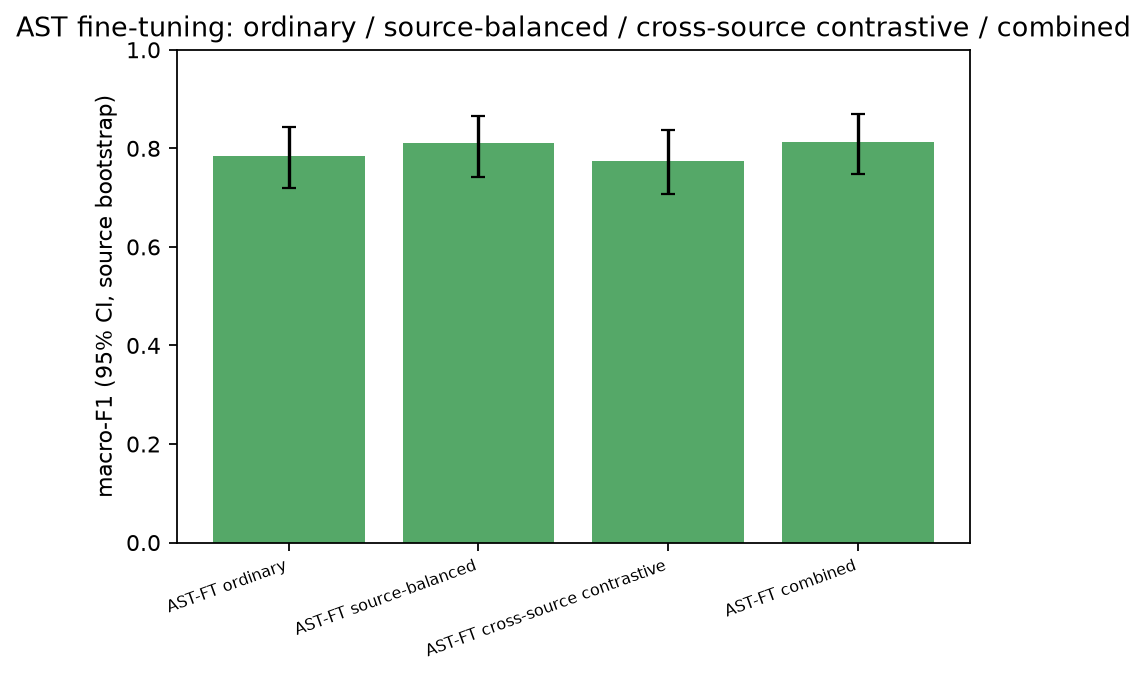

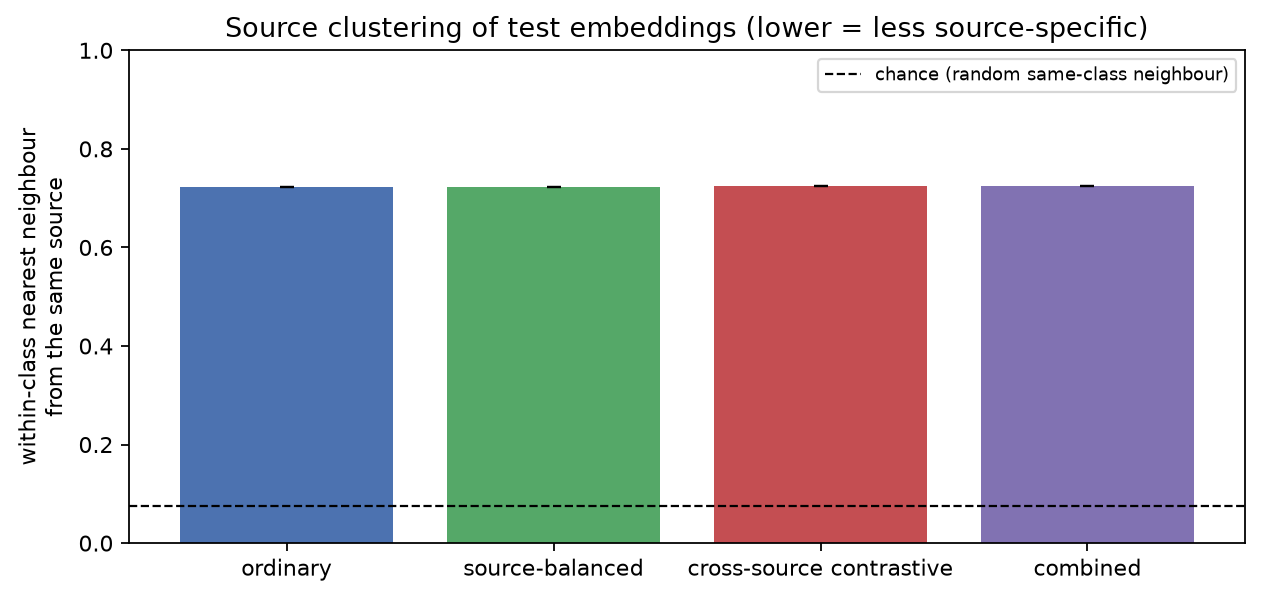

In [9]:
from IPython.display import Image
eff = pd.read_csv(RESULTS / "report" / "ast_2x2_effects.csv")
display(eff.round(4))
display(Image(str(RESULTS / "report" / "G6_ast_2x2_source_aware_training.png")))
display(Image(str(RESULTS / "report" / "G9_source_clustering_of_embeddings.png")))